In [1]:
import torch
import torch.nn as nn
import torchvision.models as models
from torchvision.models import ResNet50_Weights

import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/processed/image_metadata.csv")

print(df.shape)
df.head()

(4139, 6)


,room,style,path,width,height,aspect_ratio
0,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,421,0.560570
1,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,472,0.500000
2,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,236,236,1.000000
3,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,183,275,0.665455
4,bathroom,boho,C:\Users\Khushi Trivedi\visual-retrieval-syste...,251,201,1.248756


In [3]:
weights = ResNet50_Weights.DEFAULT
resnet = models.resnet50(weights=weights)
print(resnet)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\Khushi Trivedi/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:10<00:00, 9.63MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [4]:
resnet.fc = nn.Identity()

In [5]:
print(resnet.fc)

Identity()


In [6]:
resnet.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [7]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
resnet = resnet.to(device)
print(device)

cpu


In [8]:
resnet_preprocess = weights.transforms()

print(resnet_preprocess)

ImageClassification(
    crop_size=[224]
    resize_size=[232]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [9]:
image_path = df.iloc[100].path
image = Image.open(image_path).convert("RGB")
processed_image = resnet_preprocess(image)
print("Original:", image.size)
print("Processed:", processed_image.shape)

Original: (236, 354)
Processed: torch.Size([3, 224, 224])


In [10]:
input_tensor = processed_image.unsqueeze(0).to(device)

print(input_tensor.shape)

torch.Size([1, 3, 224, 224])


In [11]:
with torch.no_grad():
    embedding = resnet(input_tensor)

print(embedding.shape)

torch.Size([1, 2048])


In [12]:
def get_resnet_embeddings_batch(image_paths):
    images = []

    for image_path in image_paths:
        image = Image.open(image_path).convert("RGB")
        image = resnet_preprocess(image)
        images.append(image)

    batch = torch.stack(images).to(device)

    with torch.no_grad():
        embeddings = resnet(batch)

    return embeddings.cpu()

In [13]:
test_paths = df["path"].iloc[:8].tolist()

test_embeddings = get_resnet_embeddings_batch(test_paths)

print(test_embeddings.shape)

torch.Size([8, 2048])


In [14]:
print(torch.isnan(test_embeddings).any())

tensor(False)


In [15]:
batch_size = 32

all_resnet_embeddings = []

for start in range(0, len(df), batch_size):
    batch_paths = df["path"].iloc[start:start + batch_size].tolist()

    batch_embeddings = get_resnet_embeddings_batch(batch_paths)

    all_resnet_embeddings.append(batch_embeddings)

    print(f"Processed {min(start + batch_size, len(df))}/{len(df)}")

Processed 32/4139
Processed 64/4139
Processed 96/4139
Processed 128/4139
Processed 160/4139
Processed 192/4139
Processed 224/4139
Processed 256/4139
Processed 288/4139
Processed 320/4139
Processed 352/4139
Processed 384/4139
Processed 416/4139
Processed 448/4139
Processed 480/4139
Processed 512/4139
Processed 544/4139
Processed 576/4139
Processed 608/4139
Processed 640/4139
Processed 672/4139
Processed 704/4139
Processed 736/4139
Processed 768/4139
Processed 800/4139
Processed 832/4139
Processed 864/4139
Processed 896/4139
Processed 928/4139
Processed 960/4139
Processed 992/4139
Processed 1024/4139
Processed 1056/4139
Processed 1088/4139
Processed 1120/4139
Processed 1152/4139
Processed 1184/4139
Processed 1216/4139
Processed 1248/4139
Processed 1280/4139
Processed 1312/4139
Processed 1344/4139
Processed 1376/4139
Processed 1408/4139
Processed 1440/4139
Processed 1472/4139
Processed 1504/4139
Processed 1536/4139
Processed 1568/4139
Processed 1600/4139
Processed 1632/4139
Processed 1664

In [16]:
all_resnet_embeddings = torch.cat(
    all_resnet_embeddings,
    dim=0
)

print(all_resnet_embeddings.shape)

torch.Size([4139, 2048])


In [17]:
all_resnet_embeddings = (
    all_resnet_embeddings /
    all_resnet_embeddings.norm(dim=1, keepdim=True)
)

In [18]:
print(all_resnet_embeddings[0].norm())

tensor(1.0000)


In [19]:
import os

os.makedirs("../data/embeddings", exist_ok=True)

torch.save(
    all_resnet_embeddings,
    "../data/embeddings/resnet_embeddings.pt"
)

In [20]:
stored_resnet_embeddings = torch.load(
    "../data/embeddings/resnet_embeddings.pt"
)

print(stored_resnet_embeddings.shape)

torch.Size([4139, 2048])


In [21]:
def get_resnet_embedding(image_path):
    image = Image.open(image_path).convert("RGB")
    image = resnet_preprocess(image).unsqueeze(0).to(device)

    with torch.no_grad():
        embedding = resnet(image)

    embedding = embedding.squeeze(0).cpu()

    # Normalize
    embedding = embedding / embedding.norm()

    return embedding

In [22]:
def retrieve_similar_resnet_images(
    query_path,
    embeddings,
    df,
    top_k=5
):
    query_embedding = get_resnet_embedding(query_path)

    similarities = embeddings @ query_embedding

    matches = df.index[df["path"] == query_path].tolist()

    if matches:
        similarities[matches[0]] = -1

    top_scores, top_indices = torch.topk(
        similarities,
        k=top_k
    )

    return top_indices, top_scores

In [23]:
query_index = 100
query_path = df.iloc[query_index].path

In [24]:
top_indices, top_scores = retrieve_similar_resnet_images(
    query_path,
    stored_resnet_embeddings,
    df,
    top_k=5
)

In [26]:
def show_image(image_path, title=None):
    image = Image.open(image_path)

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")

    if title:
        plt.title(title)

    plt.show()

1. bathroom | boho | similarity=0.6857


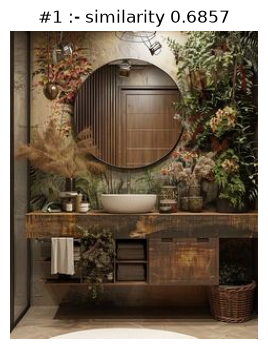

2. bathroom | minimalist | similarity=0.6791


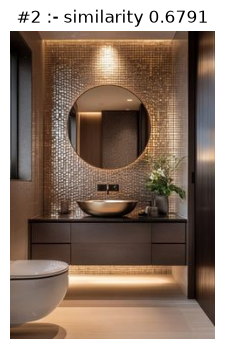

3. kitchen | boho | similarity=0.6783


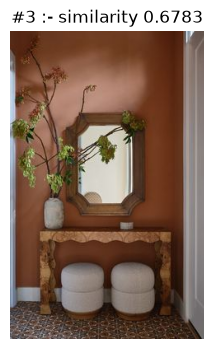

4. bathroom | industrial | similarity=0.6716


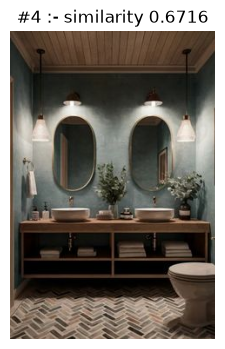

5. bathroom | boho | similarity=0.6701


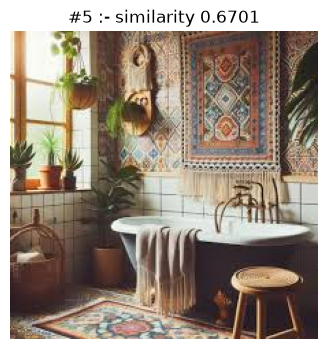

In [28]:
for rank, (index, score) in enumerate(
    zip(top_indices, top_scores),
    start=1
):
    row = df.iloc[index.item()]

    print(
        f"{rank}. {row.room} | {row.style} | "
        f"similarity={score.item():.4f}"
    )

    show_image(
        row.path,
        f"#{rank} :- similarity {score.item():.4f}"
    )